<a href="https://colab.research.google.com/github/kirajnj/Fake-News-Detection-RNN-vs-LSTM-vs-GRU/blob/main/Fake_News.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install torchtext==0.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 6.0 MB/s eta 0:00:00


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 81.1 MB/s eta 0:00:00


In [ ]:
!python -m spacy download en_core_web_sm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 56.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchtext
import random
import matplotlib.pyplot as plt
import numpy as np
import gensim

from torchtext.data import Field, LabelField, Dataset
from torchtext.data import BucketIterator
from tqdm import tqdm
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, auc
from torchtext.data import Example
from gensim.models import Word2Vec
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split




In [ ]:
# для воспроизводимости
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# Проверяем наличие GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Используем устройство: {device}")

Используем устройство: cuda


## Загружаю данные

In [ ]:
file_path = '/content/drive/MyDrive/FakeNewsNet.csv'

In [ ]:
df = pd.read_csv(file_path, encoding='utf-8')

print(f": {df.shape}")
print("Первые 5 строк:")
print(df.head())

: (23196, 5)
Первые 5 строк:
                                               title  \
0  Kandi Burruss Explodes Over Rape Accusation on...   
1  People's Choice Awards 2018: The best red carp...   
2  Sophia Bush Sends Sweet Birthday Message to 'O...   
3  Colombian singer Maluma sparks rumours of inap...   
4  Gossip Girl 10 Years Later: How Upper East Sid...   

                                            news_url        source_domain  \
0  http://toofab.com/2017/05/08/real-housewives-a...           toofab.com   
1  https://www.today.com/style/see-people-s-choic...        www.today.com   
2  https://www.etonline.com/news/220806_sophia_bu...     www.etonline.com   
3  https://www.dailymail.co.uk/news/article-33655...  www.dailymail.co.uk   
4  https://www.zerchoo.com/entertainment/gossip-g...      www.zerchoo.com   

   tweet_num  real  
0         42     1  
1          0     1  
2         63     1  
3         20     1  
4         38     1  


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23196 entries, 0 to 23195
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   title          23196 non-null  object
 1   news_url       22866 non-null  object
 2   source_domain  22866 non-null  object
 3   tweet_num      23196 non-null  int64 
 4   real           23196 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 906.2+ KB


In [ ]:
df.describe()

,tweet_num,real
count,23196.000000,23196.000000
mean,88.956803,0.751897
std,488.694592,0.431921
min,0.000000,0.000000
25%,11.000000,1.000000
50%,37.000000,1.000000
75%,65.000000,1.000000
max,29060.000000,1.000000


## Подготовка данных

In [ ]:
# Оставляем только нужные столбцы
columns_to_keep = ['title', 'news_url', 'source_domain', 'real']
df = df[columns_to_keep]

In [ ]:
# проверяем пропуски
df.isnull().sum()

,0
title,0
news_url,330
source_domain,330
real,0


In [ ]:
# Удаляем строки с пропущенными значениями
df = df.dropna()
print(f"Размер датасета после удаления null: {df.shape}")

Размер датасета после удаления null: (22866, 4)


In [ ]:
# Проверяем баланс классов
print("Распределение классов : 0 - фейк, 1 - реальная")
print(df['real'].value_counts())

Распределение классов : 0 - фейк, 1 - реальная
real
1    17371
0     5495
Name: count, dtype: int64


In [ ]:
# Создаём комбинированный текст
df['text'] = df['title'] + " " + df['news_url'] + " " + df['source_domain']

# оставляем только 'text' и 'real'
df = df[['text', 'real']]

print(f"Итоговый датасет:")
print(f"Размер: {df.shape}")
print(f"Столбцы: {df.columns.tolist()}")
print("Пример готовых данных:")

print(df.head(3))

Итоговый датасет:
Размер: (22866, 2)
Столбцы: ['text', 'real']
Пример готовых данных:
                                                text  real
0  Kandi Burruss Explodes Over Rape Accusation on...     1
1  People's Choice Awards 2018: The best red carp...     1
2  Sophia Bush Sends Sweet Birthday Message to 'O...     1


In [ ]:
# Сделаем сбалансированную выборку 50/50
# Разделяем данные на два класса
df_fake = df[df['real'] == 0].copy()
df_real = df[df['real'] == 1].copy()
print(f"Количество фейков: {len(df_fake)}")
print(f"Количество реальных: {len(df_real)}")


Количество фейков: 5495
Количество реальных: 17371


In [ ]:
test_size_per_class = min(1000, len(df_fake))
print(f"Размер тестовой выборки для каждого класса: {test_size_per_class}")
test_fake = df_fake.sample(n=test_size_per_class, random_state=SEED)
test_real = df_real.sample(n=test_size_per_class, random_state=SEED)

# Сохраняем индексы для удаления
test_indices = test_fake.index.union(test_real.index)

# Создаем тестовую выборку
test_df = pd.concat([test_fake, test_real], ignore_index=True)

# Остальные данные используем для обучения
train_df = df.drop(test_indices)

train_df = train_df.sample(frac=1, random_state=SEED).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print(f"Размер обучающей выборки: {len(train_df)}")
print(f"Размер тестовой выборки: {len(test_df)}")
# Проверяем баланс классов в новой выборке
print("Распределение классов в ОБУЧАЮЩЕЙ выборке:")
print(train_df['real'].value_counts())
print(f"Доля фейков: {train_df['real'].value_counts(normalize=True)[0]:.2%}")
print(f"Доля реальных: {train_df['real'].value_counts(normalize=True)[1]:.2%}")

print("Распределение классов в ТЕСТОВОЙ выборке:")
print(test_df['real'].value_counts())
print(f"Доля фейков: {test_df['real'].value_counts(normalize=True)[0]:.2%}")
print(f"Доля реальных: {test_df['real'].value_counts(normalize=True)[1]:.2%}")

print(f"Тестовая выборка: фейков={len(test_df[test_df['real']==0])}, реальных={len(test_df[test_df['real']==1])}")

Размер тестовой выборки для каждого класса: 1000
Размер обучающей выборки: 20866
Размер тестовой выборки: 2000
Распределение классов в ОБУЧАЮЩЕЙ выборке:
real
1    16371
0     4495
Name: count, dtype: int64
Доля фейков: 21.54%
Доля реальных: 78.46%
Распределение классов в ТЕСТОВОЙ выборке:
real
1    1000
0    1000
Name: count, dtype: int64
Доля фейков: 50.00%
Доля реальных: 50.00%
Тестовая выборка: фейков=1000, реальных=1000


In [ ]:
TEXT = Field(
    sequential=True,
    tokenize='spacy',
    lower=True,
    tokenizer_language='en_core_web_sm',
    stop_words='english'
)
LABEL = LabelField(dtype=torch.float)

In [ ]:
# создаём датасет из df
def create_dataset_from_df(dataframe, text_field, label_field):
    examples = []
    for _, row in dataframe.iterrows():
        examples.append(Example.fromlist(
            [row['text'], row['real']],
            fields=[('text', text_field), ('label', label_field)]
        ))
    return Dataset(examples, fields=[('text', text_field), ('label', label_field)])

In [ ]:
train_data = create_dataset_from_df(train_df, TEXT, LABEL)
test_data = create_dataset_from_df(test_df, TEXT, LABEL)

print(f"Train: {len(train_data)}, Test: {len(test_data)}")

Train: 20866, Test: 2000


In [ ]:
TEXT.build_vocab(train_data, max_size=20000, min_freq=2)  # ограничиваю, убираю редкие слова
LABEL.build_vocab(train_data)
print(f"Размер словаря: {len(TEXT.vocab)}")


Размер словаря: 11779


In [ ]:
# Итераторы
BATCH_SIZE = 30
train_iterator, test_iterator = BucketIterator.splits(
    (train_data, test_data),
    batch_size=BATCH_SIZE,
    device=device,
    sort_within_batch=True,
    sort_key=lambda x: len(x.text)
)
print(f"Train батчей: {len(train_iterator)}, Test батчей: {len(test_iterator)}")

Train батчей: 696, Test батчей: 67


In [ ]:
BATCH_SIZE = 30
train_iterator, test_iterator = BucketIterator.splits(
    (train_data, test_data),
    batch_size=BATCH_SIZE,
    device=device,
    sort_within_batch=True,
    sort_key=lambda x: len(x.text)
)
print(f"Train батчей: {len(train_iterator)}, Test батчей: {len(test_iterator)}")

Train батчей: 696, Test батчей: 67


## WORD2VEC

In [ ]:
EMBEDDING_DIM = 64

In [ ]:
# Обучаем Word2Vec на предложениях
sentences = [[word for word in example.text] for example in train_data.examples]

w2v_model = Word2Vec(
    vector_size=EMBEDDING_DIM,
    window=5,
    min_count=1,
    workers=4
)
w2v_model.build_vocab(sentences)
w2v_model.train(sentences, total_examples=w2v_model.corpus_count, epochs=10)
w2v_model.save('w2v_model.txt')
w2v_model = Word2Vec.load('w2v_model.txt')

In [ ]:
# Создаём embedding матрицу
words = TEXT.vocab.itos
word2vec_vectors = np.zeros((len(words), EMBEDDING_DIM))

for i, word in enumerate(words):
    if word in w2v_model.wv:
        word2vec_vectors[i] = w2v_model.wv[word]
    else:
        word2vec_vectors[i] = np.random.normal(scale=0.6, size=(EMBEDDING_DIM,))

pre_trained_emb = torch.FloatTensor(word2vec_vectors)
print(f"pre_trained_emb размер: {pre_trained_emb.shape}")


pre_trained_emb размер: torch.Size([11779, 64])


## Функции

In [ ]:
# параметры
INPUT_DIM = len(TEXT.vocab)
OUTPUT_DIM = 1

# RNN
RNN_HIDDEN_DIM = 16
RNN_LAYERS = 1
RNN_DROPOUT = 0
RNN_FREEZE = True

# LSTM
LSTM_HIDDEN_DIM = 32
LSTM_LAYERS = 2
LSTM_DROPOUT = 0.5
LSTM_FREEZE = True

# GRU
GRU_HIDDEN_DIM = 32
GRU_LAYERS = 2
GRU_DROPOUT = 0.5
GRU_FREEZE = True

In [ ]:
def binary_accuracy(preds, y):
    rounded_preds = torch.round(torch.sigmoid(preds))
    correct = (rounded_preds == y).float()
    return correct.sum() / len(correct)

In [ ]:
# проходит 1 раз по всем батчам
def train(model, iterator, optimizer, criterion):
    epoch_loss = 0
    epoch_acc = 0
    model.train()
    for batch in iterator:
        optimizer.zero_grad()
        predictions = model(batch.text)
        loss = criterion(predictions, batch.label)
        acc = binary_accuracy(predictions, batch.label)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        epoch_acc += acc.item()
    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [ ]:
def evaluate(model, iterator, criterion):
    epoch_loss = 0
    epoch_acc = 0
    model.eval()
    with torch.no_grad():
        for batch in iterator:
            predictions = model(batch.text)
            loss = criterion(predictions, batch.label)
            acc = binary_accuracy(predictions, batch.label)
            epoch_loss += loss.item()
            epoch_acc += acc.item()
    return epoch_loss / len(iterator), epoch_acc / len(iterator)

In [ ]:
def evaluate_model(model, iterator, model_name='Model'):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for batch in iterator:
            predictions = model(batch.text)
            probs = torch.sigmoid(predictions)
            preds = torch.round(probs)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch.label.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    accuracy = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds)
    roc_auc = roc_auc_score(all_labels, all_probs)

    print(f"{model_name} - Тестовая выборка:")
    print(f" Accuracy:  {accuracy:.4f}")
    print(f" F1 Score:  {f1:.4f}")
    print(f" ROC AUC:   {roc_auc:.4f}")

    # ROC кривая
    fpr, tpr, _ = roc_curve(all_labels, all_probs)
    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {roc_auc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {model_name}')
    plt.legend()
    plt.grid(True)
    plt.show()

    return accuracy, f1, roc_auc

In [ ]:
def check_overfitting(train_losses, val_losses, train_accs, val_accs, model_name='Model'):
    print(f"{model_name} - Проверка переобучения:")
    print(f"  Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f} | Разница: {val_losses[-1] - train_losses[-1]:.4f}")
    print(f"  Train Acc:  {train_accs[-1]*100:.2f}% | Val Acc: {val_accs[-1]*100:.2f}% | Разница: {(train_accs[-1] - val_accs[-1])*100:.2f}%")

    diff = (train_accs[-1] - val_accs[-1]) * 100
    if diff > 10:
        print("явное переобучение")
    elif diff > 5:
        print("небольшое переобучение 5-10%)")
    else:
        print("переобучения нет")

    return diff

In [ ]:
# criterion
train_labels = [example.label for example in train_data.examples]
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
pos_weight = torch.tensor([class_weights[0] / class_weights[1]]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
print(f"pos_weight: {pos_weight.item():.4f}")

pos_weight: 3.6420


In [ ]:
class BaseModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, pretrained_emb, rnn_type='RNN', dropout=0.5, freeze=True):
        super().__init__()
        self.embedding = nn.Embedding.from_pretrained(pretrained_emb, freeze=freeze)

        if rnn_type == 'RNN':
            self.rnn = nn.RNN(embedding_dim, hidden_dim, n_layers, dropout=dropout, batch_first=False)
        elif rnn_type == 'LSTM':
            self.rnn = nn.LSTM(embedding_dim, hidden_dim, n_layers, dropout=dropout, batch_first=False)
        else:  # GRU
            self.rnn = nn.GRU(embedding_dim, hidden_dim, n_layers, dropout=dropout, batch_first=False)

        self.fc = nn.Linear(hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)
        self.rnn_type = rnn_type

    def forward(self, text):
        embedded = self.embedding(text)
        output, hidden = self.rnn(embedded)

        # Для LSTM hidden
        if isinstance(hidden, tuple):
            hidden = hidden[0]

        hidden = self.dropout(hidden[-1, :, :])
        return self.fc(hidden).squeeze(1)

In [ ]:
# функция обучения
def train_model(model, model_name, train_iter, test_iter, optimizer, criterion, n_epochs=10, patience=3):
    train_losses, train_accs = [], []
    val_losses, val_accs = [], []

    best_val_acc = 0
    best_model_state = None
    patience_counter = 0

    print(f"обучение {model_name}")

    for epoch in tqdm(range(n_epochs)):
        train_loss, train_acc = train(model, train_iter, optimizer, criterion)
        val_loss, val_acc = evaluate(model, test_iter, criterion)

        print(f"Epoch {epoch+1:02}: Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = model.state_dict().copy()
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping на эпохе {epoch+1}")
            break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    print(f"Лучшая модель: Val Acc = {best_val_acc*100:.2f}%")

    # Графики
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label='Train Loss', marker='o')
    plt.plot(val_losses, label='Val Loss', marker='o')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.title(f'{model_name} - Loss')
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(train_accs, label='Train Acc', marker='o')
    plt.plot(val_accs, label='Val Acc', marker='o')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.title(f'{model_name} - Accuracy')
    plt.grid(True)

    plt.tight_layout()
    plt.show()

    # Проверка переобучения
    check_overfitting(train_losses, val_losses, train_accs, val_accs, model_name)

    return model, train_losses, val_losses, train_accs, val_accs

## RNN

In [ ]:
model_rnn = BaseModel(
    vocab_size=INPUT_DIM,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=RNN_HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    n_layers=RNN_LAYERS,
    pretrained_emb=pre_trained_emb,
    rnn_type='RNN',
    dropout=RNN_DROPOUT,
    freeze=RNN_FREEZE
).to(device)

optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=0.001, weight_decay=0)

обучение RNN


 10%|█         | 1/10 [00:02<00:20,  2.30s/it]

Epoch 01: Train Loss: 0.9649, Train Acc: 69.70% | Val Loss: 1.4108, Val Acc: 67.94%


 20%|██        | 2/10 [00:04<00:15,  2.00s/it]

Epoch 02: Train Loss: 0.8845, Train Acc: 74.02% | Val Loss: 1.4228, Val Acc: 69.53%


 30%|███       | 3/10 [00:05<00:13,  1.91s/it]

... (3 outputs left out)

 50%|█████     | 5/10 [00:09<00:09,  1.85s/it]

Epoch 05: Train Loss: 0.8440, Train Acc: 74.51% | Val Loss: 1.3495, Val Acc: 71.77%


 50%|█████     | 5/10 [00:11<00:11,  2.30s/it]

Epoch 06: Train Loss: 0.8146, Train Acc: 77.89% | Val Loss: 1.1820, Val Acc: 72.79%
Early stopping на эпохе 6
Лучшая модель: Val Acc = 73.78%


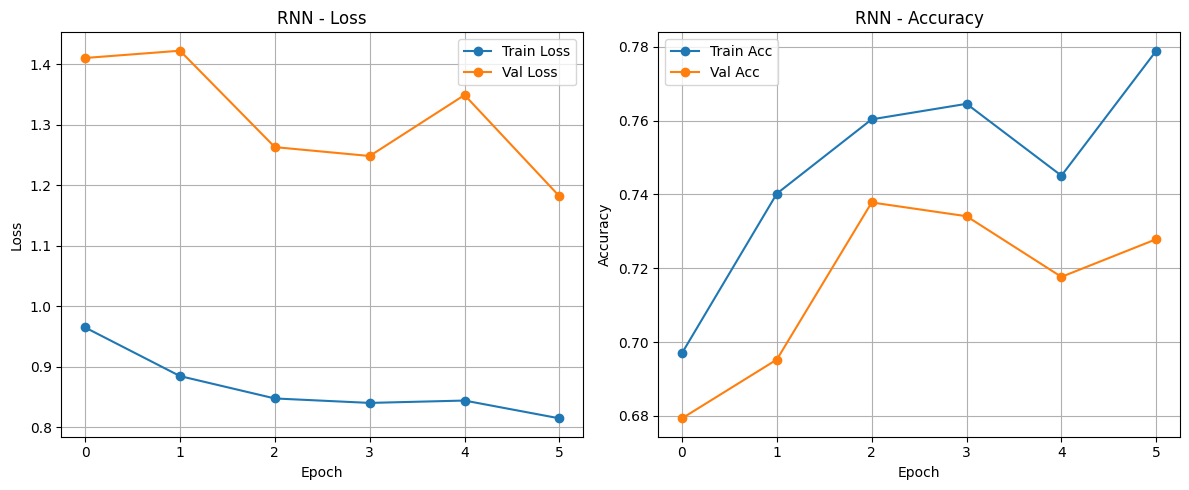

RNN - Проверка переобучения:
  Train Loss: 0.8146 | Val Loss: 1.1820 | Разница: 0.3674
  Train Acc:  77.89% | Val Acc: 72.79% | Разница: 5.10%
небольшое переобучение 5-10%)


In [ ]:
model_rnn, train_losses_rnn, val_losses_rnn, train_accs_rnn, val_accs_rnn = train_model(
    model_rnn, 'RNN', train_iterator, test_iterator, optimizer_rnn, criterion, n_epochs=10, patience=3
)


RNN - Тестовая выборка:
 Accuracy:  0.7280
 F1 Score:  0.7258
 ROC AUC:   0.8055


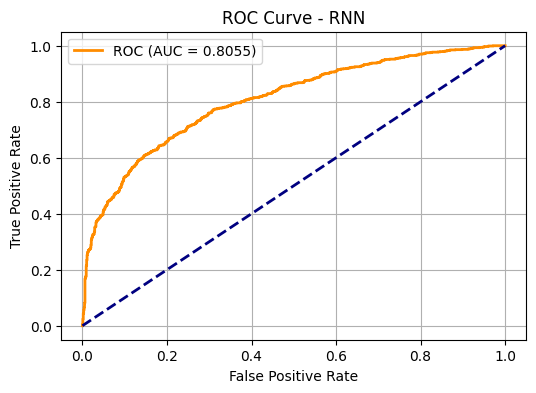

In [ ]:
accuracy_rnn, f1_rnn, roc_auc_rnn = evaluate_model(model_rnn, test_iterator, 'RNN')

## LSTM

In [ ]:
model_lstm = BaseModel(
    vocab_size=INPUT_DIM,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=LSTM_HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    n_layers=LSTM_LAYERS,
    pretrained_emb=pre_trained_emb,
    rnn_type='LSTM',
    dropout=LSTM_DROPOUT,
    freeze=LSTM_FREEZE
).to(device)

optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=0.001, weight_decay=1e-4)

обучение LSTM


 10%|█         | 1/10 [00:02<00:20,  2.28s/it]

Epoch 01: Train Loss: 0.8796, Train Acc: 75.08% | Val Loss: 1.4788, Val Acc: 72.39%


 20%|██        | 2/10 [00:04<00:18,  2.30s/it]

Epoch 02: Train Loss: 0.7931, Train Acc: 78.36% | Val Loss: 1.1646, Val Acc: 76.29%


 30%|███       | 3/10 [00:07<00:19,  2.75s/it]

... (11 outputs left out)

 90%|█████████ | 9/10 [00:22<00:02,  2.62s/it]

Epoch 09: Train Loss: 0.6858, Train Acc: 81.66% | Val Loss: 1.0786, Val Acc: 77.19%


100%|██████████| 10/10 [00:25<00:00,  2.53s/it]

Epoch 10: Train Loss: 0.6772, Train Acc: 81.86% | Val Loss: 1.2262, Val Acc: 77.66%
Лучшая модель: Val Acc = 77.66%


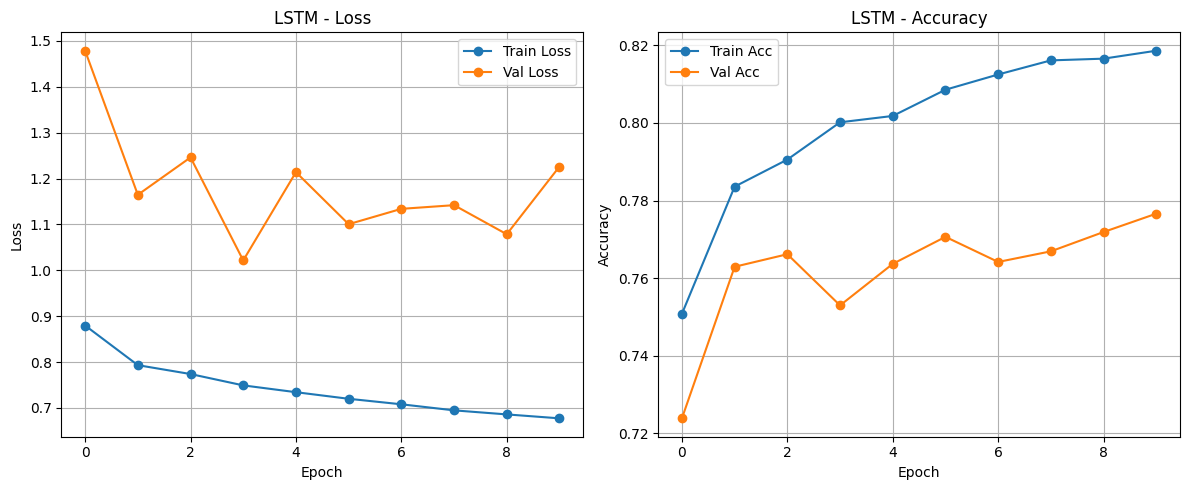

LSTM - Проверка переобучения:
  Train Loss: 0.6772 | Val Loss: 1.2262 | Разница: 0.5490
  Train Acc:  81.86% | Val Acc: 77.66% | Разница: 4.20%
переобучения нет


In [ ]:
model_lstm, train_losses_lstm, val_losses_lstm, train_accs_lstm, val_accs_lstm = train_model(
    model_lstm, 'LSTM', train_iterator, test_iterator, optimizer_lstm, criterion, n_epochs=10, patience=3
)

LSTM - Тестовая выборка:
 Accuracy:  0.7760
 F1 Score:  0.7617
 ROC AUC:   0.8520


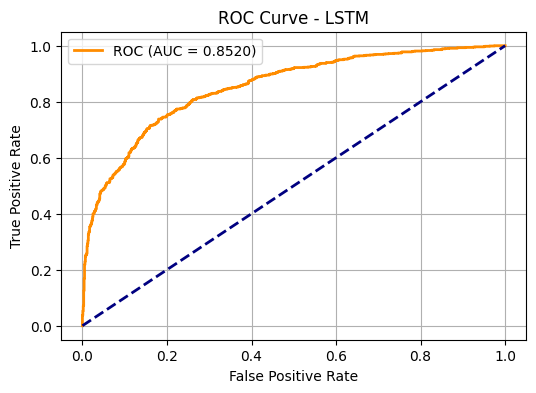

In [ ]:
accuracy_lstm, f1_lstm, roc_auc_lstm = evaluate_model(model_lstm, test_iterator, 'LSTM')

## GRU

In [ ]:
model_gru = BaseModel(
    vocab_size=INPUT_DIM,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=GRU_HIDDEN_DIM,
    output_dim=OUTPUT_DIM,
    n_layers=GRU_LAYERS,
    pretrained_emb=pre_trained_emb,
    rnn_type='GRU',
    dropout=GRU_DROPOUT,
    freeze=GRU_FREEZE
).to(device)

optimizer_gru = optim.Adam(model_gru.parameters(), lr=0.001, weight_decay=1e-4)


обучение GRU


 10%|█         | 1/10 [00:02<00:20,  2.27s/it]

Epoch 01: Train Loss: 0.8769, Train Acc: 72.47% | Val Loss: 1.2510, Val Acc: 74.83%


 20%|██        | 2/10 [00:05<00:20,  2.57s/it]

Epoch 02: Train Loss: 0.7959, Train Acc: 78.11% | Val Loss: 1.0325, Val Acc: 74.80%


 30%|███       | 3/10 [00:07<00:17,  2.57s/it]

... (11 outputs left out)

 90%|█████████ | 9/10 [00:21<00:02,  2.47s/it]

Epoch 09: Train Loss: 0.7043, Train Acc: 80.61% | Val Loss: 1.2148, Val Acc: 77.31%


100%|██████████| 10/10 [00:25<00:00,  2.56s/it]

Epoch 10: Train Loss: 0.6872, Train Acc: 80.63% | Val Loss: 1.0300, Val Acc: 78.11%
Лучшая модель: Val Acc = 78.11%


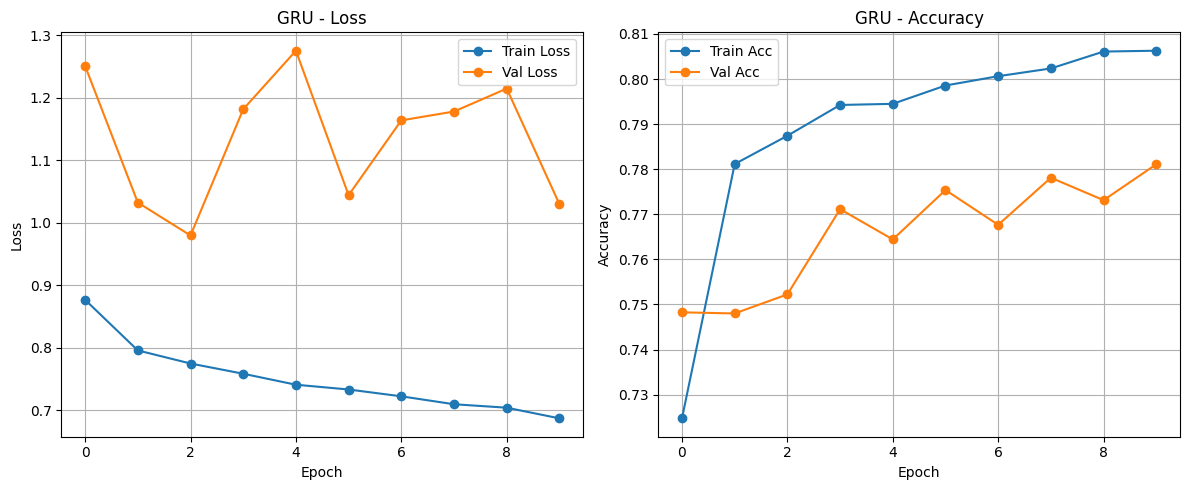

GRU - Проверка переобучения:
  Train Loss: 0.6872 | Val Loss: 1.0300 | Разница: 0.3428
  Train Acc:  80.63% | Val Acc: 78.11% | Разница: 2.52%
переобучения нет


In [ ]:
model_gru, train_losses_gru, val_losses_gru, train_accs_gru, val_accs_gru = train_model(
    model_gru, 'GRU', train_iterator, test_iterator, optimizer_gru, criterion, n_epochs=10, patience=3
)

GRU - Тестовая выборка:
 Accuracy:  0.7805
 F1 Score:  0.7851
 ROC AUC:   0.8537


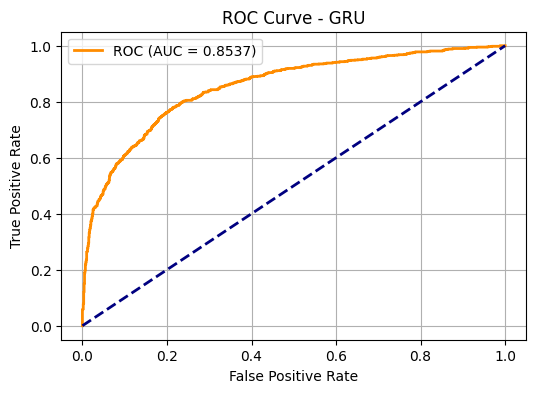

In [ ]:
accuracy_gru, f1_gru, roc_auc_gru = evaluate_model(model_gru, test_iterator, 'GRU')

In [ ]:
results = pd.DataFrame({
    'Model': ['RNN', 'LSTM', 'GRU'],
    'Accuracy': [accuracy_rnn, accuracy_lstm, accuracy_gru],
    'F1 Score': [f1_rnn, f1_lstm, f1_gru],
    'ROC AUC': [roc_auc_rnn, roc_auc_lstm, roc_auc_gru]
})
print(results.to_string(index=False))

Model  Accuracy  F1 Score  ROC AUC
  RNN    0.7280  0.725806 0.805481
 LSTM    0.7760  0.761702 0.851993
  GRU    0.7805  0.785120 0.853705


STM и GRU значительно превзошли RNN по всем метрикам.

Для повышения качества моделей сделано следующее:

- удалены стоп-слова и редкие слова (min_freq=2)

- применена балансировка классов с помощью pos_weight

- использована заморозка эмбеддингов (freeze=True) для снижения переобучения

- добавлен Dropout для LSTM и GRU

- Early stopping для автоматической остановки обучения при отсутствии улучшений

GRU показал результаты выше, чем LSTM, при одинаковых гиперпараметрах:

-объём обучающей выборки  20 866 примеров - этого недостаточно для LSTM

-тексты в датасете не длинные, поэтому дополнительный забывающий вентиль LSTM не даёт никакого преимущества

-GRU имеет меньше параметров, быстрее обучается, лучше обобщается на малых данных
